# Avance 2: conexión e integración de información de Yelp

En este avance realicé una consulta a la API de Yelp para buscar restaurantes en Miami. La búsqueda devolvió **100 negocios**. Revisé la estructura JSON, separé los datos generales de cada negocio y sus categorías y guardé los resultados en dos archivos CSV para utilizarlos en el Avance 3.

La clave se lee desde los Secrets de Google Colab con el nombre `YELP_API_KEY`. No está escrita en el notebook ni se incluye en el repositorio.

## 1. Importo las librerías

Uso `requests` para consultar la API y `pandas` para ordenar los datos. También uso `matplotlib` y `seaborn` para los gráficos.

In [34]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='deep')

print('Librerías importadas correctamente.')

Librerías importadas correctamente.


## 2. Cargo la base de clientes

Cargo la base anonimizada del primer avance para mantener la misma ciudad de trabajo. La comparación por preferencias se realiza en el Avance 3, usando la base de clientes y los resultados exportados de Yelp.

In [4]:
def encontrar_carpeta_datos():
    rutas_posibles = [
        Path("Datos"), Path("../Datos"), Path("../../Datos"),
        Path("../../../Datos"), Path("/content/Datos"),
    ]
    for ruta in rutas_posibles:
        if ruta.is_dir():
            return ruta
    ruta = Path("Datos")
    ruta.mkdir(parents=True, exist_ok=True)
    return ruta

carpeta_datos = encontrar_carpeta_datos()


def buscar_archivo(nombre):
    rutas_posibles = [
        Path(nombre), carpeta_datos / nombre, Path("../Datos") / nombre,
        Path("../../Datos") / nombre, Path("../../../Datos") / nombre,
        Path("/content") / nombre, Path("/content/Datos") / nombre,
        Path("/mnt/data") / nombre,
    ]
    for ruta in rutas_posibles:
        if ruta.exists():
            return ruta
    try:
        from google.colab import files
        print(f"No encontré {nombre}. Seleccionalo para subirlo.")
        archivos_subidos = files.upload()
        if nombre in archivos_subidos:
            return Path("/content") / nombre
    except ImportError:
        pass
    raise FileNotFoundError(f"No encontré {nombre}. Guardalo en Datos o subilo a Colab.")

ruta_clientes = buscar_archivo("base_clientes_sin_datos_contacto.csv")
df_clientes = pd.read_csv(ruta_clientes)
print("Base de clientes cargada:", df_clientes.shape)
print("Clientes de Miami:", df_clientes["ciudad_residencia"].astype(str).str.strip().str.casefold().eq("miami").sum())

Base de clientes cargada: (30000, 13)
Clientes de Miami: 3186


## 3. Defino la búsqueda

La ciudad elegida es Miami, Florida, porque también aparece en la base de clientes. La consulta busca restaurantes y solicita como máximo 100 resultados, distribuidos en páginas de hasta 50 negocios.

In [6]:
CIUDAD_BUSQUEDA = "Miami, FL"
TERMINO_BUSQUEDA = "restaurants"
MAX_RESULTADOS = 100
LIMITE_POR_SOLICITUD = 50

print("Término de búsqueda:", TERMINO_BUSQUEDA)
print("Ubicación:", CIUDAD_BUSQUEDA)
print("Máximo de resultados solicitado:", MAX_RESULTADOS)
print("Límite por solicitud:", LIMITE_POR_SOLICITUD)

Término de búsqueda: restaurants
Ubicación: Miami, FL
Máximo de resultados solicitado: 100
Límite por solicitud: 50


### 3.1. Parámetros de la búsqueda

Uso el endpoint Business Search de Yelp. La función que aparece más adelante realiza la paginación, revisa el código de respuesta y reúne los resultados antes de transformarlos en tablas.

In [8]:
print("La consulta se prepara para buscar restaurantes en Miami.")
print("El resultado se revisará por ID de negocio para evitar contar dos veces un mismo local.")

La consulta se prepara para buscar restaurantes en Miami.
El resultado se revisará por ID de negocio para evitar contar dos veces un mismo local.


## 4. Conexión a Yelp

Consulto el endpoint **Business Search** de Yelp (`/v3/businesses/search`). La clave se envía en el encabezado `Authorization` con el formato `Bearer`.

Para no dejar la clave visible en el código, la guardo en los Secrets de Google Colab con el nombre exacto `YELP_API_KEY`. La siguiente celda intenta leerla desde allí.

Documentación: [Yelp Business Search](https://docs.developer.yelp.com/reference/v3_business_search) y [Yelp Places Authentication](https://docs.developer.yelp.com/docs/places-authentication).

In [54]:
# Leo la clave desde los Secrets de Colab o desde una variable de entorno.
# No escribo ni muestro la clave directamente en el notebook.

API_KEY = None

try:
    from google.colab import userdata
    API_KEY = userdata.get('YELP_API_KEY')
except ImportError:
    # Esta alternativa sirve si el notebook se ejecuta fuera de Google Colab.
    API_KEY = os.getenv('YELP_API_KEY')
except Exception as error:
    # Si Colab no permite leer el Secret, pruebo con una variable de entorno.
    API_KEY = os.getenv('YELP_API_KEY')
    if not API_KEY:
        print('No pude leer el Secret de Colab:', type(error).__name__)

if API_KEY:
    API_KEY = API_KEY.strip()
    print('Clave YELP_API_KEY encontrada. No se muestra por seguridad.')
else:
    print('No se encontró YELP_API_KEY.')
    print('En Colab, agregá un Secret con ese nombre y activá el acceso para este notebook.')
    print('Sin la clave, la búsqueda en vivo no se ejecutará y se podrá usar el CSV entregado.')


Clave YELP_API_KEY encontrada. No se muestra por seguridad.


### 4.1. Función para hacer la consulta

La función recibe el término de búsqueda y la ciudad. Solicita hasta 100 negocios en páginas de hasta 50 resultados, usando el parámetro `offset` para avanzar a la siguiente página. Si ocurre un error, muestra el código HTTP y el detalle devuelto por la API.

In [39]:
URL_BUSQUEDA = 'https://api.yelp.com/v3/businesses/search'


def consultar_yelp(term='restaurants', location='Miami, FL', max_resultados=100):
    if not API_KEY:
        raise ValueError('Falta configurar YELP_API_KEY antes de consultar Yelp.')

    encabezados = {
        'Authorization': f'Bearer {API_KEY}',
        'accept': 'application/json'
    }

    resultados = []
    total_reportado = None
    limite_pagina = 50

    for offset in range(0, min(max_resultados, 240), limite_pagina):
        cantidad = min(limite_pagina, max_resultados - offset)
        parametros = {
            'term': term,
            'location': location,
            'limit': cantidad,
            'offset': offset,
            'sort_by': 'best_match'
        }

        respuesta = requests.get(
            URL_BUSQUEDA,
            headers=encabezados,
            params=parametros,
            timeout=30
        )

        if respuesta.status_code != 200:
            print('Código HTTP:', respuesta.status_code)
            print('Detalle devuelto por Yelp:', respuesta.text[:500])
            respuesta.raise_for_status()

        datos = respuesta.json()
        total_reportado = datos.get('total', total_reportado)
        negocios_pagina = datos.get('businesses', [])
        resultados.extend(negocios_pagina)

        if len(negocios_pagina) < cantidad:
            break
        if total_reportado is not None and len(resultados) >= min(total_reportado, max_resultados):
            break

    return {'total': total_reportado, 'businesses': resultados}

print('La función de consulta quedó definida.')

La función de consulta quedó definida.


### 4.2. Ejecuto la búsqueda

Con la clave disponible, consulté restaurantes de Miami. Yelp informó 5.900 resultados para los parámetros de búsqueda y la consulta reunió los primeros 100 negocios en dos solicitudes. El total informado por Yelp no es la cantidad descargada.

In [40]:
respuesta_api = None
consulta_api_realizada = False

if API_KEY:
    try:
        respuesta_api = consultar_yelp(
            term='restaurants',
            location='Miami, FL',
            max_resultados=100
        )
        cantidad_recibida = len(respuesta_api.get('businesses', []))

        if cantidad_recibida > 0:
            consulta_api_realizada = True
            print('Consulta a Yelp realizada correctamente.')
            print('Total informado por Yelp para esta búsqueda:', respuesta_api.get('total'))
            print('Negocios recibidos en esta consulta:', cantidad_recibida)
        else:
            print('La consulta respondió, pero Yelp no devolvió negocios para estos parámetros.')
    except requests.HTTPError as error:
        print('Yelp respondió con un error HTTP.')
        print('Detalle:', error)
    except requests.RequestException as error:
        print('Hubo un problema de conexión:', error)
    except Exception as error:
        print('No se pudo realizar la consulta:', type(error).__name__, str(error))
else:
    print('No se ejecutó una consulta en vivo porque falta la API Key.')


Consulta a Yelp realizada correctamente.
Total informado por Yelp para esta búsqueda: 5900
Negocios recibidos en esta consulta: 100


### 4.3. Reviso la respuesta JSON

La respuesta de Yelp trae los negocios dentro de una lista. Algunos campos, como categorías, ubicación y coordenadas, están organizados en listas o diccionarios dentro de cada negocio. En la siguiente celda muestro un ejemplo de esa estructura.

In [41]:
if respuesta_api is not None and respuesta_api.get('businesses'):
    print('Claves principales del JSON:')
    print(respuesta_api.keys())

    print('Claves del primer negocio:')
    print(respuesta_api['businesses'][0].keys())

    print('Ejemplo de un negocio recibido:')
    display(pd.json_normalize(respuesta_api['businesses'][:2]).head())
else:
    print('No hay una respuesta JSON en vivo para mostrar en esta ejecución.')
    print('La estructura de los campos del archivo local se revisa en las siguientes secciones.')

Claves principales del JSON:
dict_keys(['total', 'businesses'])
Claves del primer negocio:
dict_keys(['id', 'alias', 'name', 'image_url', 'is_closed', 'url', 'review_count', 'categories', 'rating', 'coordinates', 'transactions', 'price', 'location', 'phone', 'display_phone', 'distance', 'business_hours', 'attributes'])
Ejemplo de un negocio recibido:


,id,alias,name,image_url,is_closed,url,review_count,categories,rating,transactions,price,phone,display_phone,distance,business_hours,coordinates.latitude,coordinates.longitude,location.address1,location.address2,location.address3,location.city,location.zip_code,location.country,location.state,location.display_address,attributes.menu_url,attributes.waitlist_reservation
0,UXHxLN3DcDGI57uDIfCuJA,olds-havana-cuban-bar-and-cocina-miami,Old's Havana Cuban Bar & Cocina,https://s3-media0.fl.yelpcdn.com/bphoto/OyMD-x...,False,https://www.yelp.com/biz/olds-havana-cuban-bar...,3301,"[{'alias': 'cuban', 'title': 'Cuban'}, {'alias...",4.40,[pickup],$$,+17865182196,(786) 518-2196,"7,038.22","[{'open': [{'is_overnight': False, 'start': '1...",25.77,-80.22,1442 SW 8th St,,,Miami,33135,US,FL,"[1442 SW 8th St, Miami, FL 33135]",https://www.oldshavana.com/menu,NaN
1,oxtMfBGmVNE18pFVuw7lFg,fratellino-coral-gables-2,Fratellino,https://s3-media0.fl.yelpcdn.com/bphoto/yGP5fN...,False,https://www.yelp.com/biz/fratellino-coral-gabl...,1944,"[{'alias': 'italian', 'title': 'Italian'}]",4.80,"[delivery, pickup, restaurant_reservation]",$$$,+17864520068,(786) 452-0068,"2,834.06","[{'open': [{'is_overnight': False, 'start': '1...",25.75,-80.26,264 Miracle Mile,,,Coral Gables,33134,US,FL,"[264 Miracle Mile, Coral Gables, FL 33134]",https://www.fratellinoristorante.com/menus/,True


### Ejemplo ilustrativo de la estructura JSON

Este ejemplo tiene valores ficticios. Lo uso para comprobar cómo se organizan algunos campos y cómo pasarlos a una tabla; no es un registro real de Yelp.

In [42]:
# Ejemplo ilustrativo basado en los campos que documenta Yelp; no son datos reales.
ejemplo_json = {
    "businesses": [
        {
            "id": "id_ejemplo",
            "name": "Restaurante de ejemplo",
            "rating": 4.5,
            "review_count": 100,
            "price": "$$",
            "categories": [{"alias": "seafood", "title": "Seafood"}],
            "location": {"address1": "Dirección de ejemplo", "city": "Miami"},
            "coordinates": {"latitude": 25.76, "longitude": -80.19}
        }
    ]
}

# json_normalize ayuda a ver los campos anidados como columnas.
display(pd.json_normalize(ejemplo_json["businesses"]))

,id,name,rating,review_count,price,categories,location.address1,location.city,coordinates.latitude,coordinates.longitude
0,id_ejemplo,Restaurante de ejemplo,4.50,100,$$,"[{'alias': 'seafood', 'title': 'Seafood'}]",Dirección de ejemplo,Miami,25.76,-80.19


## 5. Paso los datos a tablas

Separo la información en dos tablas: una con un registro por negocio y otra con las categorías de cada negocio. Así puedo contar las calificaciones y las reseñas una sola vez por local, sin perder sus distintas categorías.

También traduzco los niveles de precio (`$`, `$$`, etc.) para que sea más fácil leerlos.

In [43]:
MAPA_PRECIOS = {
    '$': 'Bajo',
    '$$': 'Medio',
    '$$$': 'Alto',
    '$$$$': 'Muy Alto'
}


def separar_respuesta_yelp(lista_negocios):
    filas_negocios = []
    filas_categorias = []

    for negocio in lista_negocios:
        ubicacion = negocio.get('location') or {}
        coordenadas = negocio.get('coordinates') or {}
        categorias = negocio.get('categories') or []

        filas_negocios.append({
            'id': negocio.get('id'),
            'alias': negocio.get('alias'),
            'name': negocio.get('name'),
            'price': MAPA_PRECIOS.get(negocio.get('price'), 'No especificado'),
            'rating': negocio.get('rating'),
            'review_count': negocio.get('review_count'),
            'distance': negocio.get('distance'),
            'coordinates_latitude': coordenadas.get('latitude'),
            'coordinates_longitude': coordenadas.get('longitude'),
            'location_address1': ubicacion.get('address1'),
            'city': ubicacion.get('city'),
            'state': ubicacion.get('state')
        })

        for categoria in categorias:
            filas_categorias.append({
                'id': negocio.get('id'),
                'name': negocio.get('name'),
                'alias': categoria.get('alias'),
                'title': categoria.get('title')
            })

    return pd.DataFrame(filas_negocios), pd.DataFrame(filas_categorias)


if respuesta_api is not None and respuesta_api.get('businesses'):
    df_api_negocios, df_api_categorias = separar_respuesta_yelp(respuesta_api['businesses'])
else:
    df_api_negocios = pd.DataFrame()
    df_api_categorias = pd.DataFrame()

print('Negocios obtenidos de la API:', len(df_api_negocios))
print('Relaciones negocio-categoría obtenidas de la API:', len(df_api_categorias))

Negocios obtenidos de la API: 100
Relaciones negocio-categoría obtenidas de la API: 270


### Pruebo cómo separar un negocio y sus categorías

Uso el ejemplo de JSON anterior para comprobar que la función arme las dos tablas como espero.

In [44]:
ejemplo_negocios, ejemplo_categorias = separar_respuesta_yelp(ejemplo_json["businesses"])
display(ejemplo_negocios[["id", "name", "rating", "review_count", "price"]])
display(ejemplo_categorias)

,id,name,rating,review_count,price
0,id_ejemplo,Restaurante de ejemplo,4.50,100,Medio


,id,name,alias,title
0,id_ejemplo,Restaurante de ejemplo,seafood,Seafood


## 6. Preparo las tablas para el análisis

Cuando la consulta en vivo devuelve resultados, los organizo en una tabla con un registro por negocio y otra con las categorías. Si no puedo volver a consultar la API, puedo cargar los CSV guardados de esta ejecución para reproducir el análisis.

In [24]:
if not df_api_negocios.empty:
    df_negocios = df_api_negocios.copy()
    df_categorias = df_api_categorias.copy()
    fuente_yelp = "consulta en vivo a Yelp API"
else:
    ruta_salida_guardada = buscar_archivo("yelp_miami_consulta_api.csv")
    ruta_categorias_guardada = buscar_archivo("yelp_miami_categorias.csv")
    df_negocios = pd.read_csv(ruta_salida_guardada)
    df_categorias = pd.read_csv(ruta_categorias_guardada)
    fuente_yelp = "CSV guardados de la consulta real a Yelp API"

# Normalizo los tipos y retiro negocios sin ID o con ID repetido.
for columna in ["rating", "review_count", "distance"]:
    if columna in df_negocios.columns:
        df_negocios[columna] = pd.to_numeric(df_negocios[columna], errors="coerce")

if "distance_km" not in df_negocios.columns and "distance" in df_negocios.columns:
    df_negocios["distance_km"] = df_negocios["distance"] / 1000

df_negocios = df_negocios.dropna(subset=["id"]).drop_duplicates(subset="id").reset_index(drop=True)
relaciones_antes = len(df_categorias)
df_categorias = df_categorias.dropna(subset=["id", "alias", "title"]).drop_duplicates(subset=["id", "alias"]).reset_index(drop=True)
relaciones_repetidas = relaciones_antes - len(df_categorias)

print("Fuente utilizada:", fuente_yelp)
print("Cantidad de negocios únicos:", len(df_negocios))
print("Relaciones negocio-categoría antes de limpiar:", relaciones_antes)
print("Relaciones repetidas eliminadas en esta ejecución:", relaciones_repetidas)
print("Relaciones negocio-categoría únicas:", len(df_categorias))
display(df_negocios.head())

Fuente utilizada: consulta en vivo a Yelp API
Cantidad de negocios únicos: 100
Relaciones negocio-categoría antes de limpiar: 270
Relaciones repetidas eliminadas en esta ejecución: 68
Relaciones negocio-categoría únicas: 202


,id,alias,name,price,rating,review_count,distance,coordinates_latitude,coordinates_longitude,location_address1,city,state,distance_km
0,UXHxLN3DcDGI57uDIfCuJA,olds-havana-cuban-bar-and-cocina-miami,Old's Havana Cuban Bar & Cocina,Medio,4.40,3301,"7,038.22",25.77,-80.22,1442 SW 8th St,Miami,FL,7.04
1,oxtMfBGmVNE18pFVuw7lFg,fratellino-coral-gables-2,Fratellino,Alto,4.80,1944,"2,834.06",25.75,-80.26,264 Miracle Mile,Coral Gables,FL,2.83
2,K3ukx2e11xTRtYBU01dmrA,salty-flame-miami,Salty Flame,No especificado,4.20,284,"9,568.05",25.76,-80.19,1414 Brickell Ave,Miami,FL,9.57
3,WqIBKxRUPXH3NqTViAHLxQ,bayshore-club-bar-and-grill-miami,Bayshore Club Bar & Grill,Alto,4.30,1085,"6,023.92",25.73,-80.23,3391 Pan American Dr,Miami,FL,6.02
4,OJeHdB5l0Is3BNmYnpsd6w,pho-nam-miami,Pho Nam,No especificado,4.60,12,"10,179.48",25.77,-80.19,270 E Flagler St,Miami,FL,10.18


## 7. Reviso la calidad del archivo

Reviso IDs vacíos o repetidos, calificaciones fuera del rango de 0 a 5 y cantidades de reseñas negativas. También miro los nombres que aparecen asociados a más de un ID. Los conservo porque pueden ser sucursales distintas.

In [46]:
resumen_calidad = pd.DataFrame({
    'nulos': df_negocios.isna().sum(),
    '% nulos': (df_negocios.isna().mean() * 100).round(2)
}).sort_values('% nulos', ascending=False)

display(resumen_calidad)

print('IDs únicos:', df_negocios['id'].nunique())
print('IDs repetidos después de limpiar:', df_negocios['id'].duplicated().sum())
print('Calificaciones fuera de 0 a 5:', ((df_negocios['rating'] < 0) | (df_negocios['rating'] > 5)).sum())
print('Reseñas negativas:', (df_negocios['review_count'] < 0).sum())
print('Distancias negativas:', (df_negocios['distance'] < 0).sum())

nombres_con_varios_ids = (
    df_negocios.groupby('name')['id'].nunique().loc[lambda serie: serie > 1]
)
print('Nombres asociados a más de un ID:', len(nombres_con_varios_ids))
if len(nombres_con_varios_ids):
    display(nombres_con_varios_ids.to_frame('cantidad_de_ids'))

,nulos,% nulos
id,0,0.00
alias,0,0.00
name,0,0.00
price,0,0.00
rating,0,0.00
review_count,0,0.00
distance,0,0.00
coordinates_latitude,0,0.00
coordinates_longitude,0,0.00
location_address1,0,0.00


IDs únicos: 100
IDs repetidos después de limpiar: 0
Calificaciones fuera de 0 a 5: 0
Reseñas negativas: 0
Distancias negativas: 0
Nombres asociados a más de un ID: 0


## 8. Análisis general de los restaurantes

Con una fila por negocio puedo revisar calificaciones, reseñas, distancia y nivel de precio sin contar varias veces un local que tenga más de una categoría.

In [47]:
columnas_numericas = ['rating', 'review_count', 'distance_km']
display(df_negocios[columnas_numericas].describe().T)

print('Distribución por nivel de precio:')
display(
    df_negocios['price'].value_counts(dropna=False)
    .rename_axis('nivel_precio')
    .to_frame('cantidad_negocios')
)

,count,mean,std,min,25%,50%,75%,max
rating,100.00,4.38,0.32,3.60,4.10,4.40,4.60,5.00
review_count,100.00,686.80,"1,107.22",4.00,93.75,269.50,792.50,"7,100.00"
distance_km,100.00,5.79,2.94,0.77,3.20,5.27,7.48,12.80


Distribución por nivel de precio:


,cantidad_negocios
nivel_precio,
Medio,41
No especificado,39
Alto,16
Bajo,3
Muy Alto,1


### 8.1. Categorías más presentes

Cuento cuántos negocios aparecen en cada categoría dentro de la muestra de 100. Un negocio puede tener más de una categoría, por eso la suma de asociaciones puede superar los 100 negocios.

In [48]:
conteo_categorias = (
    df_categorias[['id', 'title']]
    .drop_duplicates()
    .groupby('title')['id']
    .nunique()
    .sort_values(ascending=False)
    .rename('cantidad_negocios')
    .reset_index()
)

display(conteo_categorias.head(15))

,title,cantidad_negocios
0,Italian,11
1,New American,10
2,Steakhouses,9
3,Cocktail Bars,9
4,Asian Fusion,8
5,Mediterranean,8
6,Seafood,8
7,Mexican,7
8,Cuban,6
9,Sushi Bars,5


### 8.2. Gráficos

Hago algunos gráficos para ver cómo se distribuyen las calificaciones, qué categorías aparecen más y cuántos negocios informan su nivel de precio.

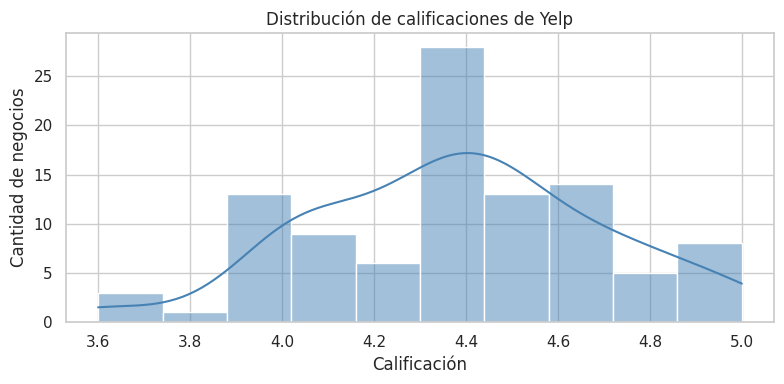

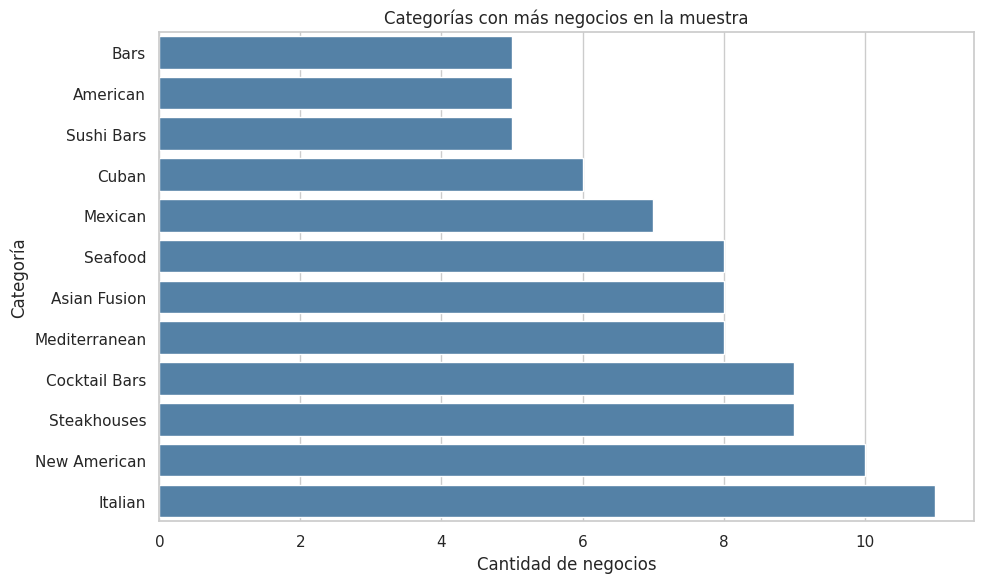

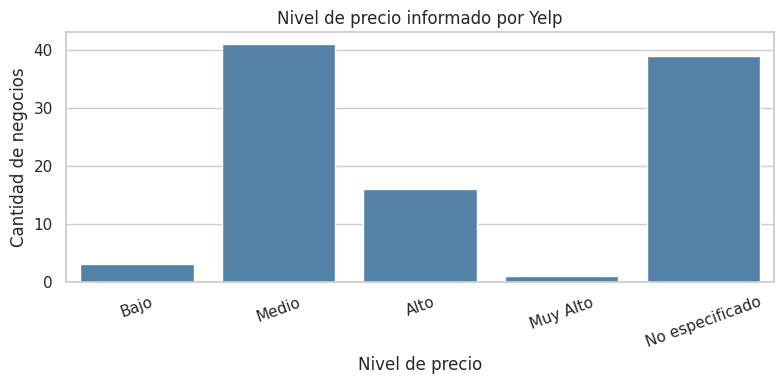

In [49]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df_negocios, x='rating', bins=10, kde=True, color='steelblue')
plt.title('Distribución de calificaciones de Yelp')
plt.xlabel('Calificación')
plt.ylabel('Cantidad de negocios')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
top_categorias = conteo_categorias.head(12).sort_values('cantidad_negocios')
sns.barplot(data=top_categorias, x='cantidad_negocios', y='title', color='steelblue')
plt.title('Categorías con más negocios en la muestra')
plt.xlabel('Cantidad de negocios')
plt.ylabel('Categoría')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
orden_precios = ['Bajo', 'Medio', 'Alto', 'Muy Alto', 'No especificado']
orden_precios = [p for p in orden_precios if p in df_negocios['price'].unique()]
sns.countplot(data=df_negocios, x='price', order=orden_precios, color='steelblue')
plt.title('Nivel de precio informado por Yelp')
plt.xlabel('Nivel de precio')
plt.ylabel('Cantidad de negocios')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 8.3. Negocios con más reseñas

Miro cuáles son los negocios con más reseñas dentro del archivo. Esto muestra su actividad en Yelp, pero no necesariamente cuántos clientes o ventas tienen.

In [50]:
top_resenas = df_negocios.nlargest(10, 'review_count')[
    ['name', 'city', 'price', 'rating', 'review_count']
].reset_index(drop=True)
display(top_resenas)

,name,city,price,rating,review_count
0,Versailles,Miami,Medio,4.00,7100
1,CVI.CHE 105,Miami,Alto,4.40,6222
2,Old's Havana Cuban Bar & Cocina,Miami,Medio,4.40,3301
3,Crazy About You,Miami,Alto,4.20,2920
4,Greenstreet Cafe,Miami,Medio,4.20,2725
5,Kyu,Miami,Alto,4.40,2131
6,Dolores But You Can Call Me Lolita,Miami,Medio,4.00,2044
7,Fratellino,Coral Gables,Alto,4.80,1944
8,Lung Yai Thai Tapas,Miami,Medio,4.00,1826
9,The Taco Stand,Miami,Medio,4.50,1763


## 9. Integro la consulta con la base de clientes

La base contiene 3.186 clientes residentes en Miami. En el Avance 3 comparo sus preferencias alimenticias con las categorías de los **100 negocios obtenidos**. Como 17 resultados corresponden a localidades cercanas, también presento por separado los 83 negocios cuya ciudad informada es exactamente Miami. Así uso toda la extracción y puedo explicar qué parte corresponde a la misma ciudad de los clientes. La comparación es contextual, no una unión fila por fila.

In [51]:
df_clientes_miami = df_clientes[
    df_clientes['ciudad_residencia'].astype(str).str.strip().str.casefold() == 'miami'
].copy()

preferencias_validas = df_clientes_miami['preferencias_alimenticias'].dropna()
tabla_preferencias = preferencias_validas.value_counts().rename_axis('preferencia').to_frame('clientes')
tabla_preferencias['porcentaje_respuestas_validas'] = (
    preferencias_validas.value_counts(normalize=True) * 100
).round(2)

display(tabla_preferencias)
print('Clientes de Miami:', len(df_clientes_miami))
print('Preferencias sin dato:', df_clientes_miami['preferencias_alimenticias'].isna().sum())

,clientes,porcentaje_respuestas_validas
preferencia,,
Mariscos,819,26.94
Vegetariano,728,23.95
Carnes,511,16.81
Vegano,382,12.57
Pescado,307,10.10
Otro,293,9.64


Clientes de Miami: 3186
Preferencias sin dato: 146


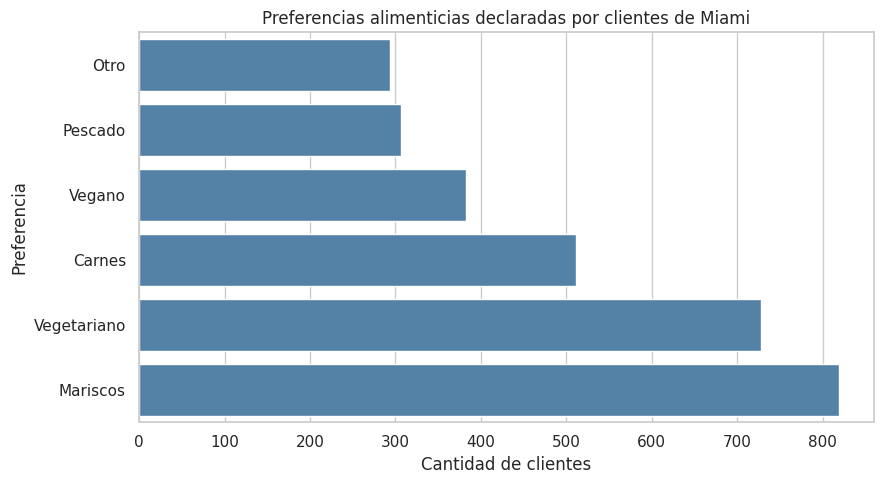

In [52]:
plt.figure(figsize=(9, 5))
orden_pref = tabla_preferencias.sort_values('clientes').index
sns.barplot(
    data=tabla_preferencias.reset_index(),
    x='clientes',
    y='preferencia',
    order=orden_pref,
    color='steelblue'
)
plt.title('Preferencias alimenticias declaradas por clientes de Miami')
plt.xlabel('Cantidad de clientes')
plt.ylabel('Preferencia')
plt.tight_layout()
plt.show()

### 9.1. Qué veo al compararlas

Las preferencias más frecuentes entre las respuestas válidas de los clientes de Miami son Mariscos (26,94%), Vegetariano (23,95%) y Vegano (12,57%). En los 100 resultados de Yelp, 8 negocios tienen la categoría Seafood y 1 tiene la etiqueta Vegan; no aparece Vegetarian. En los 83 negocios cuya ciudad informada es Miami, 6 tienen Seafood y no aparecen las etiquetas Vegetarian ni Vegan.

La comparación es contextual: no permite saber qué cliente visita cada restaurante ni asegurar que una categoría ausente signifique que el local no tiene platos de ese tipo. El desarrollo y los gráficos de esta comparación quedan en el Avance 3 del notebook `Avance_EDA.ipynb`.

## 10. Qué encontré

La consulta devolvió 100 negocios únicos y el proceso de transformación dejó 202 relaciones negocio-categoría únicas. Los resultados se revisaron por ID para evitar contar varias veces un local. Los campos de calificación, reseñas, precio, distancia y localidad quedan disponibles para el análisis.

## 11. Guardo las tablas

Guardo por separado los datos generales de los 100 negocios y sus 202 relaciones únicas con categorías. Estos dos archivos se utilizan en el Avance 3. La clave de acceso no se guarda en ninguno de ellos.

In [41]:
# Guardo siempre los archivos de la consulta real, tanto si acabo de consultar como si cargué los CSV guardados.
carpeta_datos.mkdir(parents=True, exist_ok=True)
ruta_salida = carpeta_datos / "yelp_miami_consulta_api.csv"
ruta_categorias_salida = carpeta_datos / "yelp_miami_categorias.csv"

df_negocios.to_csv(ruta_salida, index=False, encoding="utf-8-sig")
df_categorias.to_csv(ruta_categorias_salida, index=False, encoding="utf-8-sig")

print("Fuente utilizada:", fuente_yelp)
print("Se guardaron los archivos:")
print("-", ruta_salida)
print("-", ruta_categorias_salida)

Fuente utilizada: consulta en vivo a Yelp API
Se guardaron los archivos:
- Datos/yelp_miami_consulta_api.csv
- Datos/yelp_miami_categorias.csv


## 12. Fuentes

- [Yelp Business Search](https://docs.developer.yelp.com/reference/v3_business_search): endpoint, parámetros, límite de resultados y paginación.
- [Yelp Places Authentication](https://docs.developer.yelp.com/docs/places-authentication): autenticación mediante clave privada en el encabezado `Bearer`.
- `base_clientes_sin_datos_contacto.csv`: base anonimizada utilizada en el Avance 1 y para contextualizar la ciudad elegida.
- `yelp_miami_consulta_api.csv` y `yelp_miami_categorias.csv`: archivos obtenidos al transformar la consulta real de Yelp.

La clave se lee desde Colab Secrets y no se incluye en el notebook ni en el repositorio.